<a href="https://colab.research.google.com/github/Abdoulaye279/Quantum-Computing/blob/main/02_error_budget.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 - Error budget

Each error source alone, then all together against the measured values (truth table 0.70-0.80, Bell fidelity 0.71(3)). Values inspired by Table 2 of the paper.

In [1]:
# colab: get the repo first
try:
    import google.colab
    !git clone -q https://github.com/Abdoulaye279/Quantum-Computing
    %cd Quantum-Computing
except ImportError:
    pass

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from cirac_zoller import *
plt.style.use("quant.mplstyle")

labels = ["SS", "SD", "DS", "DD"]

ideal                truth table 1.000   Bell 1.000


thermal bus 2%       truth table 0.999   Bell 0.999


addressing 5%        truth table 0.981   Bell 0.979


intensity 3%         truth table 0.991   Bell 0.992


phase noise 0.3 rad  truth table 0.804   Bell 0.775


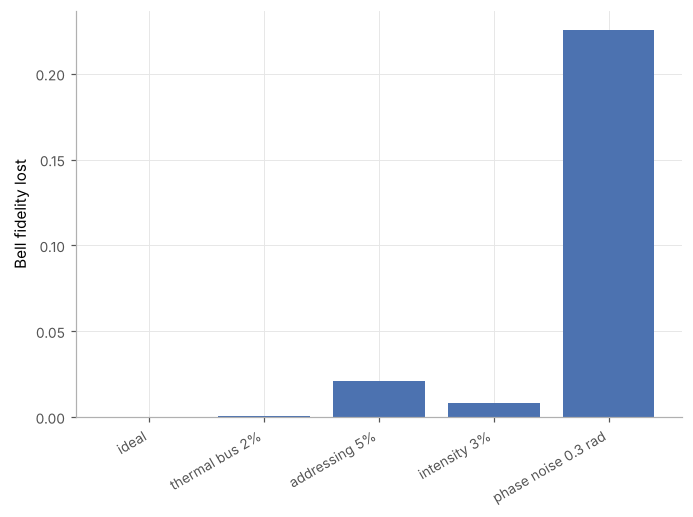

In [3]:
cases = {
    "ideal": dict(),
    "thermal bus 2%": dict(nth=0.02),        # 2% chance of starting in n=1
    "addressing 5%": dict(eps=0.05),         # 5% of each pulse on the other ion
    "intensity 3%": dict(amp_sig=0.03),      # rotation angles off by 3% (std)
    "phase noise 0.3 rad": dict(ph_sig=0.3), # random laser phase on each pulse
}
res = {}
for name, kw in cases.items():
    T = truth_table(shots=150, **kw)
    res[name] = (diag_mean(T), bell_fidelity(run(bell_input, shots=150, **kw)))
    print(f"{name:20s} truth table {res[name][0]:.3f}   Bell {res[name][1]:.3f}")

plt.bar(range(len(res)), [1 - v[1] for v in res.values()])
plt.xticks(range(len(res)), res.keys(), rotation=30, ha="right")
plt.ylabel("Bell fidelity lost"); plt.tight_layout(); plt.show()
# phase noise is by far the biggest: ~22% lost on the Bell fidelity. addressing ~2%, intensity ~1%, thermal 2% almost nothing

truth table mean 0.784 (paper 0.70-0.80)   Bell 0.734 (paper 0.71)


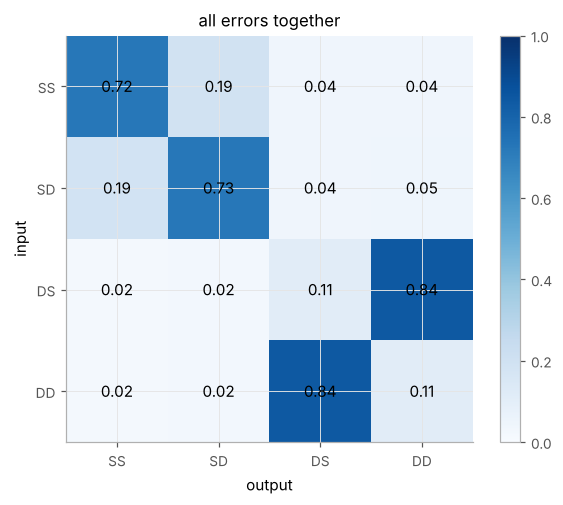

In [4]:
kw = dict(nth=0.02, eps=0.05, amp_sig=0.03, ph_sig=0.32)
Tn = truth_table(shots=300, **kw)
rn = run(bell_input, shots=300, **kw)
print("truth table mean", round(diag_mean(Tn), 3), "(paper 0.70-0.80)   Bell", round(bell_fidelity(rn), 3), "(paper 0.71)")
plt.imshow(Tn, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(4), labels); plt.yticks(range(4), labels)
plt.xlabel("output"); plt.ylabel("input")
for i in range(4):
    for j in range(4):
        plt.text(j, i, f"{Tn[i, j]:.2f}", ha="center", va="center")
plt.title("all errors together"); plt.colorbar(); plt.show()
# sigma_phi = 0.32 rad was picked to land near the measured Bell fidelity, so this is a fit, not a prediction
# the truth table (0.78) then falls inside the measured range on its own

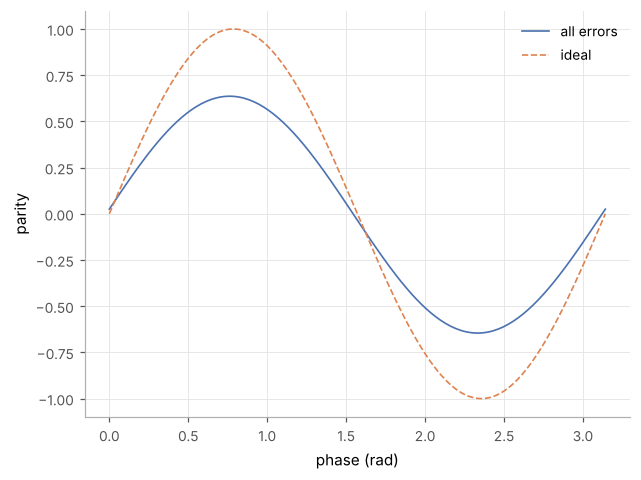

In [5]:
phis = np.linspace(0, np.pi, 200)
plt.plot(phis, parity_curve(rn, phis), label="all errors")
plt.plot(phis, parity_curve(run(bell_input, shots=1), phis), "--", label="ideal")
plt.xlabel("phase (rad)"); plt.ylabel("parity"); plt.legend(); plt.show()
# contrast of the parity fringe drops, same as in the paper